# 05 - EDA & Report Visualizations
**Owner:** Emanuel  
**Goal:** Create clear visuals for interpreting the exploratory data analysis and reporting project results.

**Inputs:** Processed game data from Notebook 2 and model comparison results from Notebook 4.  
**Output:** Figures saved in `reports/figures/`. Run the required upstream notebooks first to refresh their outputs.

## Setup

In [8]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

PROCESSED = Path("../data/processed")
REPORTS = Path("../reports")
FIGURES = REPORTS / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression


## Load and prepare the EDA data

In [9]:
df = pd.read_csv(PROCESSED / "games_processed.csv")
TARGET = "HOME_TEAM_WINS"
ALL_FEATURES = [c for c in df.columns if c.endswith("_diff")]
NICE = {
    "FG_PCT_diff": "FG% diff",
    "FT_PCT_diff": "FT% diff",
    "FG3_PCT_diff": "3P% diff",
    "AST_diff": "Assists diff",
    "REB_diff": "Rebounds diff",
    "TOV_diff": "Turnovers diff",
}

# Use all games for score-based and season-level visuals.
# Use the complete sample for visuals that compare all six box-score features.
complete = df.dropna(subset=ALL_FEATURES + [TARGET]).copy()
complete["Outcome"] = complete[TARGET].map({1: "Home win", 0: "Home loss"})

print(f"All games: {len(df):,}; complete feature sample: {len(complete):,}")
print(f"Seasons: {df['season'].min()}–{df['season'].max()} ({df['season'].nunique()} seasons)")
print("Features available for plotting:", [NICE.get(c, c) for c in ALL_FEATURES])

All games: 31,230; complete feature sample: 16,816
Seasons: 2000–2025 (26 seasons)
Features available for plotting: ['FG% diff', 'FT% diff', '3P% diff', 'Assists diff', 'Rebounds diff', 'Turnovers diff']


## EDA visualization workspace

Use `df` for season-level or outcome visuals that only need complete game results. Use `complete` when comparing the six difference features, so missing statistics are not treated as zero. Save finished figures to `FIGURES` with descriptive filenames.

## Model Performance Comparison

This figure reads the metrics exported by Notebook 04; it does not rerun model training.

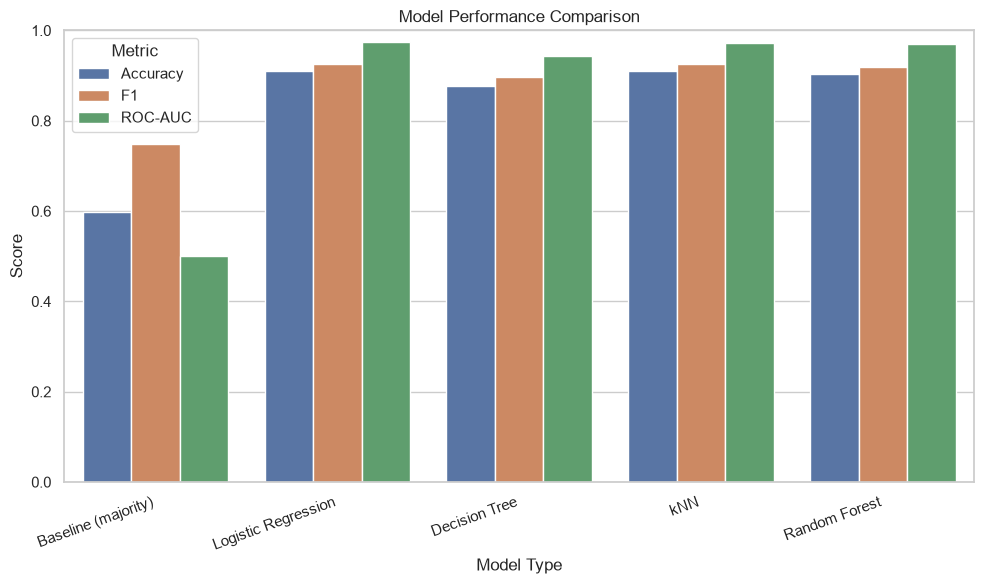

In [10]:
results_df = pd.read_csv(REPORTS / "model_comparison.csv", index_col="Model")
metrics = ["Accuracy", "F1", "ROC-AUC"]
plot_data = results_df.reset_index().melt(
    id_vars="Model", value_vars=metrics, var_name="Metric", value_name="Score"
)
model_order = results_df.index.tolist()

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    data=plot_data, x="Model", y="Score", hue="Metric",
    order=model_order, hue_order=metrics, ax=ax
)
ax.set(
    title="Model Performance Comparison",
    xlabel="Model Type",
    ylabel="Score",
    ylim=(0, 1),
)
ax.set_yticks(np.linspace(0, 1, 6))
ax.legend(title="Metric")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(FIGURES / "model_metric_comparison.png", dpi=160, bbox_inches="tight")
plt.show()

## Final Model Coefficient Importance

Refit the training-only logistic regression search used in Notebook 04, then plot its fitted coefficients. Because the pipeline standardizes inputs, each coefficient reflects a one-standard-deviation feature change.


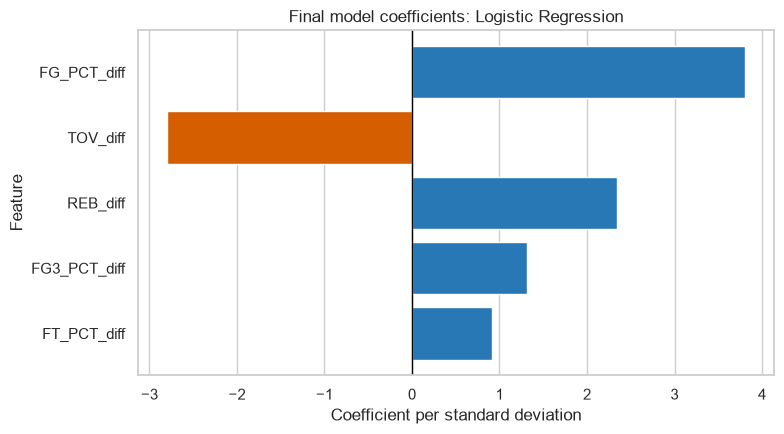

In [11]:
# Match Notebook 04: select by training-fold ROC-AUC and refit the logistic pipeline.
COEFFICIENT_FEATURES = [
    "FG_PCT_diff", "TOV_diff", "REB_diff", "FG3_PCT_diff", "FT_PCT_diff"
]
final_model_name = results_df["CV ROC-AUC"].dropna().idxmax()
if final_model_name != "Logistic Regression":
    raise ValueError(f"Expected logistic regression as the selected final model, got {final_model_name!r}")

modeling = df.loc[df["season"] <= 2015].dropna(
    subset=COEFFICIENT_FEATURES + [TARGET]
).copy()
X, y = modeling[COEFFICIENT_FEATURES], modeling[TARGET].astype(int)
X_train, _, y_train, _ = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
logistic_search = GridSearchCV(
    Pipeline([
        ("scale", StandardScaler()),
        ("clf", LogisticRegression(max_iter=1000)),
    ]),
    {"clf__C": [0.01, 0.1, 1, 10]},
    cv=cv,
    scoring="roc_auc",
    n_jobs=2,
)
logistic_search.fit(X_train, y_train)
final_pipeline = logistic_search.best_estimator_
final_logistic = final_pipeline.named_steps["clf"]

coefficient_table = pd.DataFrame({
    "feature": COEFFICIENT_FEATURES,
    "coefficient": final_logistic.coef_.ravel(),
}).sort_values("coefficient", key=lambda values: values.abs())

bar_colors = np.where(coefficient_table["coefficient"] >= 0, "#2878B5", "#D55E00")
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.barh(coefficient_table["feature"], coefficient_table["coefficient"], color=bar_colors)
ax.axvline(0, color="black", linewidth=1)
ax.set(
    title=f"Final model coefficients: {final_model_name}",
    xlabel="Coefficient per standard deviation",
    ylabel="Feature",
)
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(FIGURES / "final_model_coefficients.png", dpi=160, bbox_inches="tight")
plt.show()
